In [35]:
import sys
print(sys.version)
print(sys.executable)

3.10.22 (main, Oct  9 2026, 15:18:58) [MSC v.1944 64 bit (AMD64)]
c:\Users\Public\AI Agent 수업\새 폴더\02_Deep_Learning_TensorFlow\.venv\Scripts\python.exe


In [36]:
"""
<타이타닉 데이터를 이용하여 생존율 예측 실습>
✨ 사용 데이터 : 03_exe/ 폴더 내에 csv 파일 사용
 - 머신러닝 분류분석, 딥러닝 DNN 사용하여 가장 좋은 모델 찾기
 - 조별 실습
   -> 제출은 각자 이름으로 파일명 만드셔서 구글드라이브 15day에 제출
   -> 제출 폴더 : 04_타이타닉_생존_예측(개별제출)
   -> 제출 파일명 : 02_(홍길동)Titanic_exe.ipynb
"""

'\n<타이타닉 데이터를 이용하여 생존율 예측 실습>\n✨ 사용 데이터 : 03_exe/ 폴더 내에 csv 파일 사용\n - 머신러닝 분류분석, 딥러닝 DNN 사용하여 가장 좋은 모델 찾기\n - 조별 실습\n   -> 제출은 각자 이름으로 파일명 만드셔서 구글드라이브 15day에 제출\n   -> 제출 폴더 : 04_타이타닉_생존_예측(개별제출)\n   -> 제출 파일명 : 02_(홍길동)Titanic_exe.ipynb\n'

In [37]:
%pip install xgboost
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
from xgboost import XGBClassifier

print("XGBoost 불러오기 성공!")

XGBoost 불러오기 성공!


In [39]:
### 사용할 라이브러리 불러들이기

# 데이터 조작을 위한 라이브러리
import pandas as pd
import numpy as np
import tensorflow as tf

# 기본 시각화 라이브러리
import matplotlib.pyplot as plt

# 통계적 시각화 라이브러리(보통 기본 시각화보다 향상된 라이브러리라고 생각하면 됨)
import seaborn as sns

# 시각화 시 그래프의 너비/높이를 기본 설정하기(단위 = 인치)
plt.rcParams["figure.figsize"] = (12, 5)

# 시각화시 한글 깨짐 처리를 위한 폰트 지정
plt.rcParams["font.family"] = "Malgun Gothic"

# 시각화시 마이너스(-) 기호 깨짐 방지 처리
plt.rcParams["axes.unicode_minus"] = False

# 상관관계 검정(scipy : 통계 라이브러리)
from scipy.stats import spearmanr, pearsonr

# 훈련/검증/테스트 데이터로 분리하는 함수
from sklearn.model_selection import train_test_split

# 데이터스케일링 표준화 클래스
from sklearn.preprocessing import StandardScaler

# 사용할 훈련모델 클래스
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from xgboost import XGBClassifier

# 분류분석 오차확인(평가) 라이브러리
# - 오차행렬표, 오차행렬도(그래프)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 모델 예측 평가지표 확인
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 분류모델 평가지표(선정기준)
# - 정확도, 정밀도, 재현율, f1-score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 군집 모델
from sklearn.cluster import KMeans, DBSCAN

# 튜닝 클래스
from sklearn.model_selection import GridSearchCV

# 지도-분류분석 평가
from sklearn.metrics import accuracy_score, confusion_matrix

# 군집분석 평가
from sklearn.metrics import silhouette_score, adjusted_rand_score

from tensorflow import keras

In [40]:
# 파일 불러오기
file_path =("./03_exe/(실습)타이타닉_분류_데이터셋.csv")

# 파일 정보 확인
df_a = pd.read_csv(file_path)
df_a.info()
display(df_a.describe())
df_a.head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [41]:
# 데이터 파일에서 사용할 컬럼 추출
df_b = df_a[["survived", "pclass", "age", "sex", "who", "sibsp", "parch", "embarked"]]

# 데이터 추출한 파일 정보 확인
df_b.info()
display(df_b.describe())
df_b.head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   age       714 non-null    float64
 3   sex       891 non-null    object 
 4   who       891 non-null    object 
 5   sibsp     891 non-null    int64  
 6   parch     891 non-null    int64  
 7   embarked  889 non-null    object 
dtypes: float64(1), int64(4), object(3)
memory usage: 55.8+ KB


,survived,pclass,age,sibsp,parch
count,891.000000,891.000000,714.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594
std,0.486592,0.836071,14.526497,1.102743,0.806057
min,0.000000,1.000000,0.420000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000
50%,0.000000,3.000000,28.000000,0.000000,0.000000
75%,1.000000,3.000000,38.000000,1.000000,0.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000


,survived,pclass,age,sex,who,sibsp,parch,embarked
0,0,3,22.0,male,man,1,0,S
1,1,1,38.0,female,woman,1,0,C
2,1,3,26.0,female,woman,0,0,S
3,1,1,35.0,female,woman,1,0,S
4,0,3,35.0,male,man,0,0,S


### 이상치 결측치 확인

In [42]:
# 컬럼 추출한 파일의 컬럼 내 이상치 및 결측치 확인
df_b.info()
df_b.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   age       714 non-null    float64
 3   sex       891 non-null    object 
 4   who       891 non-null    object 
 5   sibsp     891 non-null    int64  
 6   parch     891 non-null    int64  
 7   embarked  889 non-null    object 
dtypes: float64(1), int64(4), object(3)
memory usage: 55.8+ KB


survived      0
pclass        0
age         177
sex           0
who           0
sibsp         0
parch         0
embarked      2
dtype: int64

In [43]:
# who컬럼에서 child와 성인남녀를 분리  (이상치를 먼저 중앙값(child를 빼고 남녀 성인 나이의 평균)으로 변경하고 결측치를 중앙값으로 채운다.) 
age_median =df_b.groupby("who")["age"].transform("median")


In [44]:
# 결측치를 중앙값으로 채우기
df_b["age"]=df_b["age"].fillna(age_median)

C:\Users\eumya\AppData\Local\Temp\ipykernel_21024\3795251575.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_b["age"]=df_b["age"].fillna(age_median)


In [45]:
# 결과확인
df_b["age"].isnull().sum()

np.int64(0)

In [46]:
df_b.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   age       891 non-null    float64
 3   sex       891 non-null    object 
 4   who       891 non-null    object 
 5   sibsp     891 non-null    int64  
 6   parch     891 non-null    int64  
 7   embarked  889 non-null    object 
dtypes: float64(1), int64(4), object(3)
memory usage: 55.8+ KB


In [74]:


#age 정수타입으로 정리하기 

df_b["age"] = df_b["age"].astype("int")
df_b.info()
df_b.head(5)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   survived  891 non-null    int64 
 1   pclass    891 non-null    int64 
 2   age       891 non-null    int64 
 3   sex       891 non-null    object
 4   who       891 non-null    object
 5   sibsp     891 non-null    int64 
 6   parch     891 non-null    int64 
 7   embarked  891 non-null    object
 8   info      891 non-null    object
dtypes: int64(5), object(4)
memory usage: 62.8+ KB


C:\Users\eumya\AppData\Local\Temp\ipykernel_21024\1664646051.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_b["age"] = df_b["age"].astype("int")


,survived,pclass,age,sex,who,sibsp,parch,embarked,info
0,0,3,22,male,man,1,0,S,man
1,1,1,38,female,woman,1,0,C,woman
2,1,3,26,female,woman,0,0,S,woman
3,1,1,35,female,woman,1,0,S,woman
4,0,3,35,male,man,0,0,S,man


In [75]:

# 엠바크 결측치 채우기 
df_b["embarked"] = df_b["embarked"].fillna(df_b["embarked"].mode()[0])

C:\Users\eumya\AppData\Local\Temp\ipykernel_21024\3817752273.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_b["embarked"] = df_b["embarked"].fillna(df_b["embarked"].mode()[0])


In [76]:
df_b.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   survived  891 non-null    int64 
 1   pclass    891 non-null    int64 
 2   age       891 non-null    int64 
 3   sex       891 non-null    object
 4   who       891 non-null    object
 5   sibsp     891 non-null    int64 
 6   parch     891 non-null    int64 
 7   embarked  891 non-null    object
 8   info      891 non-null    object
dtypes: int64(5), object(4)
memory usage: 62.8+ KB


In [77]:
# 데이터 who의 데이터를 personal에 변수로 
# age, sex, who를 이용하여 info 컬럼 생성

# 컬럼명 소문자로 변경
# 나이와 성별을 이용하여 child, old, man, woman 분류

# who 컬럼에 이미 있는 child, man, woman 분류를 그대로 사용
# 61세 이상인 승객만 old로 변경
# info = child(17세 이하), man, woman(18~60세), old(61세 이상)

df_b["info"] = df_b["who"]
df_b.loc[df_b["age"] >= 61, "info"] = "old"

# 잘 만들어졌는지 확인
print(df_b["info"].value_counts())
print(df_b[["age", "who", "info"]].head(10))

# info에 포함된 기존 정보는 중복되므로 제거
#df_b = df_b.drop(columns=["who", "sex", "age"])
print("전체 승객 수 :", len(df_b))
df_b.head()

info
man      518
woman    268
child     83
old       22
Name: count, dtype: int64
   age    who   info
0   22    man    man
1   38  woman  woman
2   26  woman  woman
3   35  woman  woman
4   35    man    man
5   30    man    man
6   54    man    man
7    2  child  child
8   27  woman  woman
9   14  child  child
전체 승객 수 : 891


C:\Users\eumya\AppData\Local\Temp\ipykernel_21024\3760979396.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_b["info"] = df_b["who"]


,survived,pclass,age,sex,who,sibsp,parch,embarked,info
0,0,3,22,male,man,1,0,S,man
1,1,1,38,female,woman,1,0,C,woman
2,1,3,26,female,woman,0,0,S,woman
3,1,1,35,female,woman,1,0,S,woman
4,0,3,35,male,man,0,0,S,man


In [78]:
# 데이터 분리 60% / 검증 20% / 테스트 20%
# survived: 정답(y), 나머지 컬럼: 입력 특성(X)
# who는 age/sex로 만든 범주이므로 info와 중복되어 제외

X = df_b.drop(columns=["survived", "who"])
y = df_b["survived"]

# 문자열 범주를 숫자 열로 변환 (원-핫 인코딩)
X = pd.get_dummies(X, columns=["sex", "embarked", "info"], dtype=int)

# 1차: 훈련 60%, 임시 40%
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)
# 2차: 임시 40%를 검증 20%, 테스트 20%로 분리
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)
print("훈련:", X_train.shape, "검증:", X_val.shape, "테스트:", X_test.shape)

# 훈련 데이터 결측치 확인
print(X_train.isnull().sum())

# 검증 데이터 결측치 확인
print(X_val.isnull().sum())

# 테스트 데이터 결측치 확인
print(X_test.isnull().sum())



훈련: (534, 13) 검증: (178, 13) 테스트: (179, 13)
pclass        0
age           0
sibsp         0
parch         0
sex_female    0
sex_male      0
embarked_C    0
embarked_Q    0
embarked_S    0
info_child    0
info_man      0
info_old      0
info_woman    0
dtype: int64
pclass        0
age           0
sibsp         0
parch         0
sex_female    0
sex_male      0
embarked_C    0
embarked_Q    0
embarked_S    0
info_child    0
info_man      0
info_old      0
info_woman    0
dtype: int64
pclass        0
age           0
sibsp         0
parch         0
sex_female    0
sex_male      0
embarked_C    0
embarked_Q    0
embarked_S    0
info_child    0
info_man      0
info_old      0
info_woman    0
dtype: int64


In [79]:
### 데이터 스케일링만 실행

ss = StandardScaler()

X_train_scaled = ss.fit_transform(X_train)
X_val_scaled = ss.transform(X_val)
X_test_scaled = ss.transform(X_test)



print("스케일링 완료:", X_train_scaled.shape)


스케일링 완료: (534, 13)


In [80]:

### 머신러닝 분류 모델 5개 훈련 평가

model_list = [
    RandomForestClassifier(random_state=42),
    ExtraTreesClassifier(random_state=42),
    GradientBoostingClassifier(random_state=42),
    HistGradientBoostingClassifier(random_state=42),
    XGBClassifier(random_state=42, eval_metric="logloss")
]

datasets = {
    "train": (X_train_scaled, y_train),
    "val": (X_val_scaled, y_val),
    "test": (X_test_scaled, y_test)
}
results = []
trained_models = {}
for model in model_list:
    model_name = model.__class__.__name__
    model.fit(X_train_scaled, y_train)
    trained_models[model_name] = model
    row = {"model": model_name}
    
    
    for data_name, (X_data, y_data) in datasets.items():
        pred = model.predict(X_data)
        row[f"{data_name}_accuracy"] = accuracy_score(y_data, pred)
        row[f"{data_name}_precision"] = precision_score(y_data, pred, zero_division=0)
        row[f"{data_name}_recall"] = recall_score(y_data, pred, zero_division=0)
        row[f"{data_name}_f1"] = f1_score(y_data, pred, zero_division=0)
    row["overfit_gap"] = row["train_accuracy"] - row["val_accuracy"]
    results.append(row)

# 모델별 성능 비교 결과 확인

df_results = pd.DataFrame(results)

display(df_results)


,model,train_accuracy,train_precision,train_recall,train_f1,val_accuracy,val_precision,val_recall,val_f1,test_accuracy,test_precision,test_recall,test_f1,overfit_gap
0,RandomForestClassifier,0.936330,0.952381,0.878049,0.913706,0.786517,0.727273,0.705882,0.716418,0.804469,0.750000,0.739130,0.744526,0.149813
1,ExtraTreesClassifier,0.936330,0.967213,0.863415,0.912371,0.814607,0.777778,0.720588,0.748092,0.754190,0.681159,0.681159,0.681159,0.121723
2,GradientBoostingClassifier,0.880150,0.885246,0.790244,0.835052,0.837079,0.842105,0.705882,0.768000,0.782123,0.777778,0.608696,0.682927,0.043071
3,HistGradientBoostingClassifier,0.891386,0.906077,0.800000,0.849741,0.853933,0.875000,0.720588,0.790323,0.804469,0.814815,0.637681,0.715447,0.037453
4,XGBClassifier,0.926966,0.941489,0.863415,0.900763,0.831461,0.827586,0.705882,0.761905,0.782123,0.750000,0.652174,0.697674,0.095506


검증 정확도 1위: GradientBoostingClassifier
검증 정확도: 0.8371


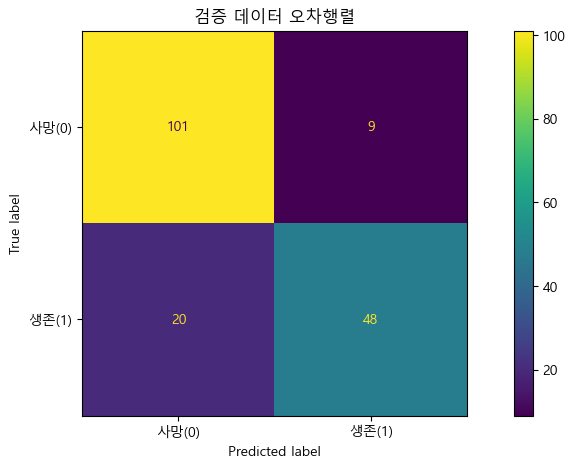

In [81]:
###검증 성능 좋은 모델 확인

best_model_name = result_df.sort_values("val_accuracy", ascending=False).iloc[0]["model"]
best_model = trained_models[best_model_name]
print("검증 정확도 1위:", best_model_name)


val_pred = best_model.predict(X_val_scaled)
print("검증 정확도:", round(accuracy_score(y_val, val_pred), 4))


cm = confusion_matrix(y_val, val_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["사망(0)", "생존(1)"]).plot()
plt.title("검증 데이터 오차행렬")
plt.show()


In [82]:
### GridSearchCV 하이퍼파라미터 튜닝

param_grids = {
    "RandomForestClassifier": {"n_estimators": [50, 100], "max_depth": [None, 10]},
    "ExtraTreesClassifier": {"n_estimators": [50, 100], "max_depth": [None, 10]},
    "GradientBoostingClassifier": {"n_estimators": [50, 100], "max_depth": [3, 5]},
    "HistGradientBoostingClassifier": {"max_iter": [50, 100], "max_depth": [None, 10]},
    "XGBClassifier": {"n_estimators": [50, 100], "max_depth": [3, 5]}
}

grid = GridSearchCV(
    estimator=trained_models[best_model_name],
    param_grid=param_grids[best_model_name],
    cv=3, scoring="accuracy", n_jobs=-1
)
grid.fit(X_train_scaled, y_train)
print("최적 파라미터:", grid.best_params_)
print("교차검증 정확도:", round(grid.best_score_, 4))


tuned_model = grid.best_estimator_
print("튜닝 후 검증 정확도:", round(accuracy_score(y_val, tuned_model.predict(X_val_scaled)), 4))



최적 파라미터: {'max_depth': 3, 'n_estimators': 50}
교차검증 정확도: 0.794
튜닝 후 검증 정확도: 0.8371


In [83]:
# 이진 분류: 출력층 유닛 1개, sigmoid
# 검증 데이터의 성능을 보면서 학습


keras.utils.set_random_seed(42)
dnn_model = keras.Sequential([
    keras.layers.Input(shape=(X_train_scaled.shape[1],)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

#환경
dnn_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

#훈련
history = dnn_model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100, batch_size=32, callbacks=[early_stop], verbose=0
)
print("DNN 학습 완료. 실행 epoch:", len(history.history["loss"]))

DNN 학습 완료. 실행 epoch: 28


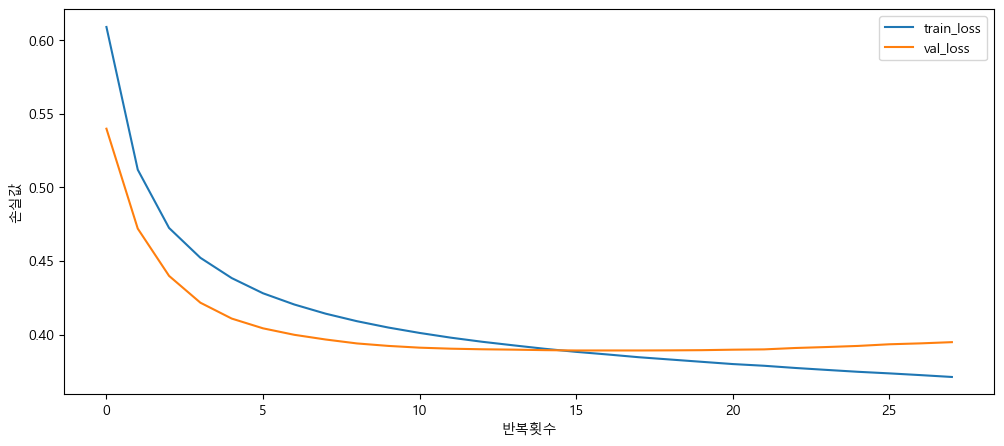

DNN 훈련 정확도: 0.8408
DNN 검증 정확도: 0.8371


In [84]:

# 훈련·검증 손실 그래프 그려보기

plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.xlabel("반복횟수")
plt.ylabel("손실값")
plt.legend()
plt.show()

def dnn_accuracy(X_data, y_data):
    prob = dnn_model.predict(X_data, verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)
    return accuracy_score(y_data, pred)

print("DNN 훈련 정확도:", round(dnn_accuracy(X_train_scaled, y_train), 4))
print("DNN 검증 정확도:", round(dnn_accuracy(X_val_scaled, y_val), 4))

최종 선택 모델: GradientBoostingClassifier (GridSearchCV)
테스트 정확도: 0.7821
테스트 정밀도: 0.8
테스트 재현율: 0.5797
테스트 F1: 0.6723


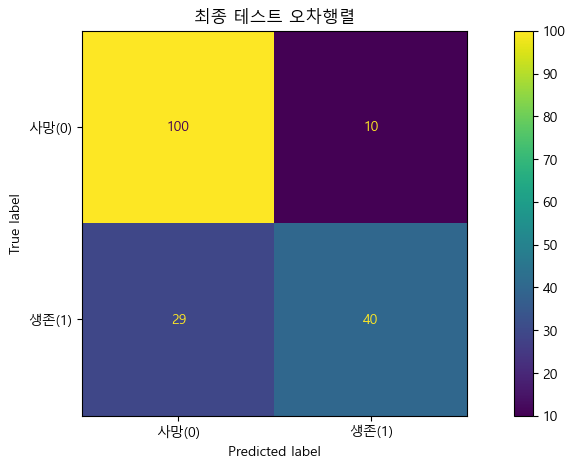

In [87]:
### 최종 모델 비교 및 테스트 평가

tuned_val_acc = accuracy_score(y_val, tuned_model.predict(X_val_scaled))
dnn_val_acc = dnn_accuracy(X_val_scaled, y_val)

if dnn_val_acc > tuned_val_acc:
    final_name = "DNN"
    final_test_pred = (dnn_model.predict(X_test_scaled, verbose=0).ravel() >= 0.5).astype(int)
else:
    final_name = best_model_name + " (GridSearchCV)"
    final_test_pred = tuned_model.predict(X_test_scaled)

print("최종 선택 모델:", final_name)
print("테스트 정확도:", round(accuracy_score(y_test, final_test_pred), 4))
print("테스트 정밀도:", round(precision_score(y_test, final_test_pred, zero_division=0), 4))
print("테스트 재현율:", round(recall_score(y_test, final_test_pred, zero_division=0), 4))
print("테스트 F1:", round(f1_score(y_test, final_test_pred, zero_division=0), 4))
ConfusionMatrixDisplay.from_predictions(y_test, final_test_pred, display_labels=["사망(0)", "생존(1)"])
plt.title("최종 테스트 오차행렬")
plt.show()

### 훈련결과


In [59]:
"""
### <훈련결과>

타이타닉 승객 891명중, 여성의 생존율은 74.20%, 남성의 18.89%

여성이 약 3.9배, 어린이의 생존율은 59.04%

객실 등급별로는 1등석 62.96%, 2등석 47.28%, 3등석 24.24%로, 상위 등급일수록 생존율이 높음

1등석 여성의 생존율은 96.81%로 매우 높음, 3등석 남성은 13.54%로 낮음

성별과 객실 등급에 따라 생존율에 차이가 나타남


"""

'\n### <훈련결과>\n\n타이타닉 승객 891명중, 여성의 생존율은 74.20%, 남성의 18.89%\n\n여성이 약 3.9배, 어린이의 생존율은 59.04%\n\n객실 등급별로는 1등석 62.96%, 2등석 47.28%, 3등석 24.24%로, 상위 등급일수록 생존율이 높음\n\n1등석 여성의 생존율은 96.81%로 매우 높음, 3등석 남성은 13.54%로 낮음\n\n성별과 객실 등급에 따라 생존율에 차이가 나타남\n\n\n'